# Implementing Quantum Oracle Sketching (QOS), step by step

This notebook builds Quantum Oracle Sketching from scratch: first as real gate-level circuits in PennyLane, then as a fast NumPy simulator that is checked against those circuits and against the authors' reference code. It ends with what happens at bank-data scale.

It accompanies the report *Quantum Oracle Sketching on Bank-Held Data* and the repository [`qos-rbc-experiments`](https://github.com/THAKKAR82/qos-rbc-experiments) (tag `v1-qos-findings`). Paper: Zhao et al., *Exponential quantum advantage in processing massive classical data*, arXiv:2604.07639.

| Part | What you build | Key idea |
|---|---|---|
| 1 | A phase oracle from a data stream, gate by gate | One data sample = one small gate |
| 2 | A circuit that uses the oracle | Every use consumes a fresh batch of samples |
| 3 | A matrix oracle (block encoding) and a toy classifier | How QOS loads a data table |
| 4 | The same ideas at bank scale | Where the costs explode |

**Presenting.** Each section opens with a one-line **In plain English** summary for non-technical listeners; the code and **Technical note** cells are for the technical audience.

Everything is a classical simulation on a laptop; nothing runs on quantum hardware. Runs in the project's main environment (`numpy`, `matplotlib`, `scikit-learn`, `pennylane`) in about a minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml
from sklearn.feature_extraction import FeatureHasher
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import SGDClassifier, LogisticRegression

rng = np.random.default_rng(42)

# One colour-blind-checked palette; at most three series per chart.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10.5, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False,
})
print("PennyLane", qml.__version__)

PennyLane 0.45.1


## Part 1. Build a phase oracle from a data stream

**In plain English:** we want the quantum computer to "know" a list of 16 yes/no tags all at once. Instead of loading the list, we let examples stream past and turn each one into a tiny rotation.

### 1.1 The target

The oracle flips the sign of every "yes" item:

$$O_f\,|x\rangle = (-1)^{f(x)}\,|x\rangle = e^{i\pi f(x)}|x\rangle .$$

It is diagonal, so it is fully described by one phase per item. 16 items need $n=4$ qubits.

In [2]:
n = 4
N = 2 ** n
f = rng.integers(0, 2, size=N)          # hidden tags; the algorithm never sees this array
target_phase = np.pi * f
target_diag = np.exp(1j * target_phase)
print("f(x) =", f)

f(x) = [0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1]


### 1.2 The data stream

QOS only ever sees a stream of random examples $(x, f(x))$, one at a time, with $x$ drawn uniformly. Nothing is stored.

In [3]:
def data_stream(f, M, rng):
    # Yield M examples (x, f(x)) with x uniform over items. A generator: nothing is kept.
    for x in rng.integers(0, len(f), size=M):
        yield int(x), int(f[x])

print(list(data_stream(f, 8, np.random.default_rng(0))))

[(13, 1), (10, 1), (8, 0), (4, 0), (4, 0), (0, 0), (1, 1), (0, 0)]


### 1.3 One sample = one gate

For each sample $(x, f(x))$, apply a small phase $\theta f(x)$ to the basis state $|x\rangle$ only, with $\theta = \pi N / M$. On average item $x$ is visited $M/N$ times, so its phases add up to $\pi f(x)$.

At gate level, "phase on $|x\rangle$ only" is a multi-controlled phase gate: control on the first $n-1$ bits of $x$, phase the last qubit, with $X$ gates to handle a 0 in the last bit.

In [4]:
def qos_gate(x, fx, theta, n):
    # Apply phase theta*f(x) to basis state |x> only (wire 0 = most significant bit).
    bits = [int(b) for b in format(x, f"0{n}b")]
    if bits[-1] == 0:
        qml.PauliX(n - 1)
    qml.ctrl(qml.PhaseShift(theta * fx, wires=n - 1),
             control=list(range(n - 1)), control_values=bits[:-1])
    if bits[-1] == 0:
        qml.PauliX(n - 1)

dev = qml.device("default.qubit", wires=n)

@qml.qnode(dev)
def sketched_state(samples, theta):
    for w in range(n):
        qml.Hadamard(w)                  # uniform superposition over all items
    for x, fx in samples:                # stream: one gate per sample, then discard it
        qos_gate(x, fx, theta, n)
    return qml.state()

demo_samples = list(data_stream(f, 3, np.random.default_rng(1)))
print("First three samples:", demo_samples)
print(qml.draw(sketched_state)(demo_samples, np.pi * N / 300))

First three samples: [(7, 1), (8, 0), (12, 1)]
0: ──H─╭○───────────╭●──────────────╭●───────────┤  State
1: ──H─├●───────────├○──────────────├●───────────┤  State
2: ──H─├●───────────├○──────────────├○───────────┤  State
3: ──H─╰Rϕ(0.17)──X─╰Rϕ(0.00)──X──X─╰Rϕ(0.17)──X─┤  State


### 1.4 Run the circuit, and check a fast simulator against it

Gate-level simulation is slow for large $M$. Because every QOS gate is diagonal, the whole sketch is just "add $\theta f(x)$ to item $x$'s phase", which NumPy can do instantly. We verify the two agree, then use NumPy for big streams.

**Technical note:** the phase vector below exists only in the *simulation*. On hardware, each sample is applied as a gate and discarded; the only "memory" is the quantum state.

In [5]:
def sketch_phases(samples, theta, N):
    # Fast simulator: accumulate each sample's phase onto its item.
    phases = np.zeros(N)
    for x, fx in samples:
        phases[x] += theta * fx
    return phases

M = 400
theta = np.pi * N / M
samples = list(data_stream(f, M, np.random.default_rng(1)))

state = sketched_state(samples, theta)                 # PennyLane, 400 gates
circuit_diag = state * np.sqrt(N)                      # amplitudes = e^{i phase_x} / sqrt(N)
numpy_diag = np.exp(1j * sketch_phases(samples, theta, N))

print(f"PennyLane vs NumPy, max difference: {np.max(np.abs(circuit_diag - numpy_diag)):.1e}")

def fast_sketch_phases(f, M, rng):
    # Vectorised version for large M: same random draws, counts visits per item.
    counts = np.bincount(rng.integers(0, len(f), size=M), minlength=len(f))
    return np.pi * len(f) / M * f * counts

same = np.allclose(fast_sketch_phases(f, M, np.random.default_rng(1)), sketch_phases(samples, theta, N))
print("Vectorised sketch identical to sample-by-sample sketch:", same)
print(f"Sketch vs exact oracle after {M} samples, worst item: "
      f"{np.max(np.abs(numpy_diag - target_diag)):.2f}")

PennyLane vs NumPy, max difference: 2.7e-15
Vectorised sketch identical to sample-by-sample sketch: True
Sketch vs exact oracle after 400 samples, worst item: 1.27


### 1.5 Why small nudges, not big flips

**In plain English:** the naive store-nothing approach (flip the sign every time an item appears) fails, because an item seen twice gets flipped back. Small nudges simply add up.

Orange arrows are the targets; blue arrows are what the stream built (first 8 items shown).

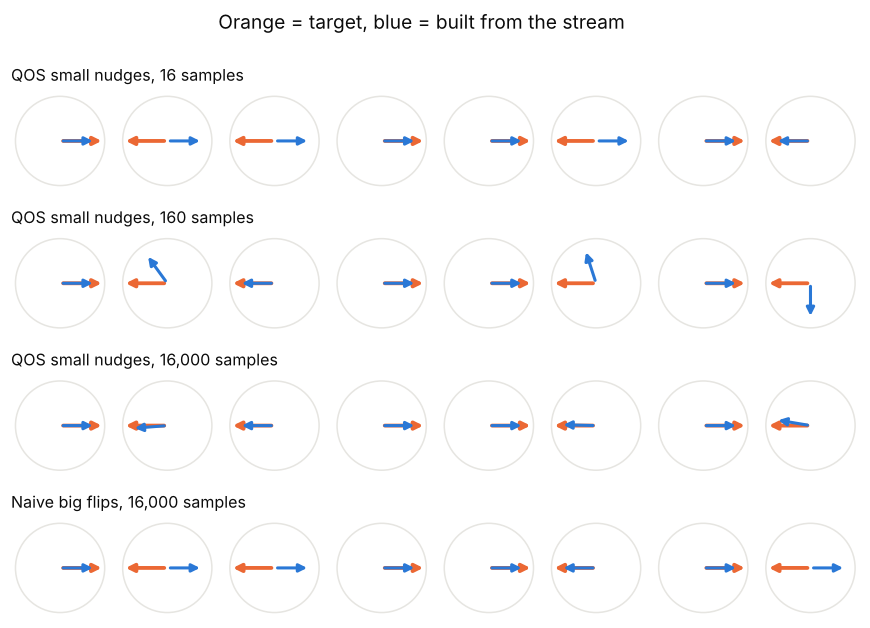

In [6]:
def big_flip_phases(samples, N):
    # Naive: flip on every visit; repeats undo each other.
    phases = np.zeros(N)
    for x, fx in samples:
        phases[x] += np.pi * fx
    return phases

def draw_dials(ax_row, phases, title, show=8):
    for x, ax in enumerate(ax_row[:show]):
        ax.set_aspect("equal"); ax.axis("off")
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=GRID, lw=1))
        t = target_phase[x]
        ax.annotate("", xy=(np.cos(t), np.sin(t)), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=2.5))
        p = phases[x]
        ax.annotate("", xy=(0.8*np.cos(p), 0.8*np.sin(p)), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2))
        ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
    ax_row[0].text(-1.1, 1.35, title, fontsize=10.5, color=INK, ha="left")

stream_rng = np.random.default_rng(7)
rows = [16, 160, 16_000]
fig, axes = plt.subplots(len(rows) + 1, 8, figsize=(10, 6.2))
for r, Mr in enumerate(rows):
    s_r = list(data_stream(f, Mr, stream_rng))
    draw_dials(axes[r], sketch_phases(s_r, np.pi * N / Mr, N), f"QOS small nudges, {Mr:,} samples")
s_r = list(data_stream(f, 16_000, stream_rng))
draw_dials(axes[-1], big_flip_phases(s_r, N), "Naive big flips, 16,000 samples")
fig.suptitle("Orange = target, blue = built from the stream", y=1.0, color=INK)
plt.subplots_adjust(hspace=0.45, wspace=0.05); plt.show()

### 1.6 How many samples? The averaged oracle

A quantum algorithm uses a *fresh* sketch each time, so what matters is the average operation over the randomness. For item $x$ visited $c_x\sim\mathrm{Binomial}(M,1/N)$ times:

$$\mathbb{E}\big[e^{i\theta f(x) c_x}\big] = \Big(1-\tfrac1N+\tfrac1N e^{i\pi N f(x)/M}\Big)^{M} \approx e^{i\pi f(x)}\,e^{-\pi^2 N f(x)/(2M)} .$$

The error is $\approx \pi^2 N/(2M)$, so reaching error $\varepsilon$ costs $M\propto N/\varepsilon$ samples. **This is exactly the formula in the reference implementation** (`q_oracle_sketch_boolean` in `qos.py`); Section 3.5 checks this against the reference implementation.

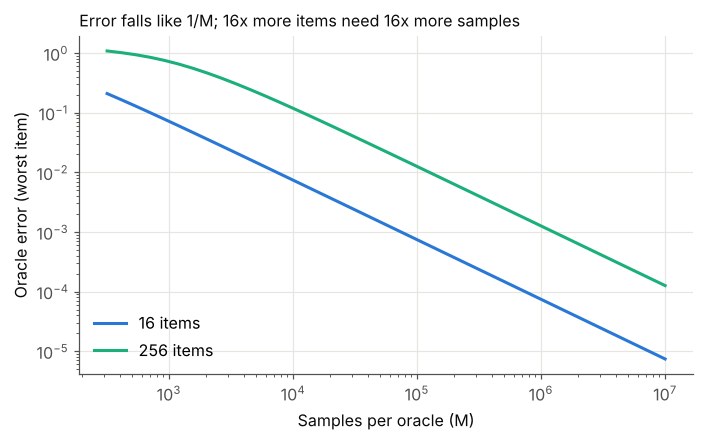

  16 items: ~7,896 samples per oracle for 1% error
 256 items: ~126,331 samples per oracle for 1% error


In [7]:
def expected_oracle(f, M):
    # Averaged QOS phase oracle (same formula as the reference qos.py).
    N = len(f)
    return (1 - 1/N + np.exp(1j * np.pi * N * f / M) / N) ** M

def oracle_error(f, M):
    return np.max(np.abs(expected_oracle(f, M) - np.exp(1j * np.pi * f)))

M_grid = np.unique(np.logspace(2.5, 7, 40).astype(int))
fig, ax = plt.subplots(figsize=(7.2, 4))
for n_items, col in [(16, BLUE), (256, AQUA)]:
    f_all = np.ones(n_items, dtype=int)                       # worst case: all "yes"
    ax.loglog(M_grid, [oracle_error(f_all, m) for m in M_grid], color=col, label=f"{n_items} items")
ax.set_xlabel("Samples per oracle (M)"); ax.set_ylabel("Oracle error (worst item)")
ax.set_title("Error falls like 1/M; 16x more items need 16x more samples",
             loc="left", color=INK, fontsize=10.5)
ax.legend(loc="lower left"); plt.show()

for n_items in (16, 256):
    print(f"{n_items:>4} items: ~{np.pi**2 * n_items / (2 * 1e-2):,.0f} samples per oracle for 1% error")

## Part 2. Use the oracle, and count the cost

**In plain English:** once built, the oracle answers a question about *all* items in one quantum step. But each use eats a fresh batch of samples, and quantum answers are random, so the step must be repeated many times.

The circuit $H^{\otimes n} O_f H^{\otimes n}$ returns $|0\dots0\rangle$ with probability $\big(\tfrac1N\sum_x(-1)^{f(x)}\big)^2$, which reveals how balanced the tags are.

In [8]:
@qml.qnode(dev)
def balance_circuit(diag):
    for w in range(n):
        qml.Hadamard(w)
    qml.DiagonalQubitUnitary(diag, wires=range(n))   # the (sketched) oracle
    for w in range(n):
        qml.Hadamard(w)
    return qml.probs(wires=range(n))

def prob_all_zero(diag):
    # NumPy shortcut: amplitude of |0...0> is the mean of the oracle's diagonal.
    return np.abs(np.mean(diag)) ** 2

# Check PennyLane against the NumPy shortcut, for the exact and a sketched oracle
sk = np.exp(1j * sketch_phases(data_stream(f, 5_000, np.random.default_rng(42)), np.pi * N / 5_000, N))
for name, diag in [("exact oracle", target_diag), ("sketched oracle", sk)]:
    diff = abs(float(balance_circuit(diag)[0]) - prob_all_zero(diag))
    print(f"{name:>16}: PennyLane vs NumPy difference {diff:.1e}")

    exact oracle: PennyLane vs NumPy difference 8.3e-17
 sketched oracle: PennyLane vs NumPy difference 1.1e-16


In [9]:
# The sample meter: every shot needs its own freshly sketched oracle.
M_per_query = 5_000
meter_rng = np.random.default_rng(3)
print(f"Exact answer: {prob_all_zero(target_diag):.4f}\n")
print(f"{'shots':>7} {'estimate':>9} {'samples consumed':>18}")
for shots in [10, 100, 1_000, 10_000]:
    hits = 0
    for _ in range(shots):
        phases = fast_sketch_phases(f, M_per_query, meter_rng)
        hits += meter_rng.random() < prob_all_zero(np.exp(1j * phases))
    print(f"{shots:>7} {hits/shots:>9.4f} {shots * M_per_query:>18,}")

Exact answer: 0.0625

  shots  estimate   samples consumed
     10    0.0000             50,000
    100    0.0700            500,000
   1000    0.0550          5,000,000


  10000    0.0574         50,000,000


## Part 3. From a list to a data table: the matrix oracle

**In plain English:** for real machine learning, QOS must load a whole table (rows = records, columns = features). The trick is the same: each streamed table entry becomes a small rotation. A second trick, using one extra qubit, turns those rotations back into the table's numbers.

### 3.1 Sketch the table

Following the reference `q_oracle_sketch_matrix_element`: each sample is a random nonzero entry $(i, j, A_{ij})$; it adds phase $\tfrac{\mathrm{nnz}}{M}\arcsin(A_{ij})$ to $|i,j\rangle$. On average this builds $U = e^{iB}$ with $B_{ij}=\arcsin(A_{ij})$.

In [10]:
def table_stream(A, M, rng):
    # Yield M random nonzero entries (i, j, A_ij) of the table.
    rows, cols = np.nonzero(A)
    for k in rng.integers(0, len(rows), size=M):
        yield int(rows[k]), int(cols[k]), float(A[rows[k], cols[k]])

def sketch_table(A, M, rng):
    # Simulator of the sketched diagonal unitary U ~ exp(i arcsin A).
    # Vectorised equivalent of looping over table_stream(A, M, rng).
    rows, cols = np.nonzero(A)
    k = rng.integers(0, len(rows), size=M)
    B = np.zeros_like(A, dtype=float)
    np.add.at(B, (rows[k], cols[k]), np.arcsin(A[rows[k], cols[k]]) * len(rows) / M)
    return np.exp(1j * B)

def expected_table(A, M):
    # Averaged version (same formula as the reference qos.py).
    nnz = np.count_nonzero(A)
    p = np.where(A != 0, 1 / nnz, 0.0)
    return np.exp(M * np.log1p(p * np.expm1(1j * nnz / M * np.arcsin(A))))

A = np.zeros((4, 4))
A[0, 1], A[1, 0], A[2, 3], A[3, 2], A[2, 2] = 0.8, -0.5, 0.3, -0.9, 0.6
print("Table A (4 x 4, 5 nonzeros):\n", A)

Table A (4 x 4, 5 nonzeros):
 [[ 0.   0.8  0.   0. ]
 [-0.5  0.   0.   0. ]
 [ 0.   0.   0.6  0.3]
 [ 0.   0.  -0.9  0. ]]


### 3.2 Block encoding with one ancilla (LCU)

Put an ancilla in superposition, apply $U$ if it is $|0\rangle$ and $U^\dagger$ if it is $|1\rangle$, then interfere. The ancilla-$|1\rangle$ block is $\tfrac{U-U^\dagger}{2} = i\sin B = iA$: **the table's values appear as amplitudes**. This is a *block encoding*, the form quantum linear-algebra algorithms consume.

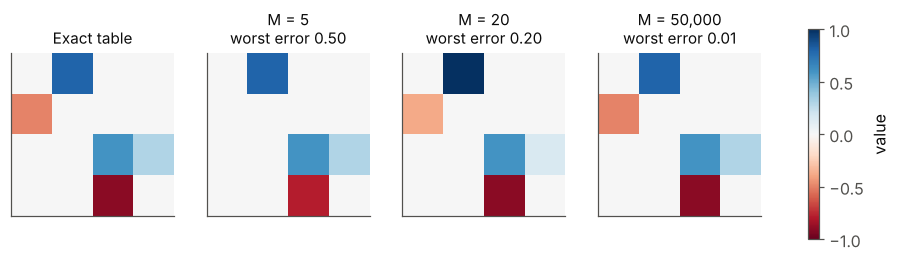

LCU circuit vs sin formula: 4.4e-16
Recovered table vs true table at M = 50,000: 0.005


In [11]:
m = 4                                         # 16 table cells -> 4 data qubits
data_wires = list(range(1, m + 1))            # wire 0 is the ancilla
dev_lcu = qml.device("default.qubit", wires=m + 1)

@qml.qnode(dev_lcu)
def block_encoding(U_diag):
    for w in data_wires:
        qml.Hadamard(w)                       # address every cell at once
    qml.Hadamard(0)
    qml.ctrl(qml.DiagonalQubitUnitary(U_diag, wires=data_wires), control=0, control_values=0)
    qml.ctrl(qml.DiagonalQubitUnitary(U_diag.conj(), wires=data_wires), control=0, control_values=1)
    qml.Hadamard(0)
    return qml.state()

def read_table(U):
    state = block_encoding(U.reshape(-1))
    ancilla_one = state[2 ** m:]              # amplitudes with ancilla = |1>
    return (ancilla_one * np.sqrt(2 ** m) / 1j).real.reshape(A.shape)

fig, axes = plt.subplots(1, 4, figsize=(11, 3.1))
panels = [("Exact table", A)]
for Mt in (5, 20, 50_000):
    T = read_table(sketch_table(A, Mt, np.random.default_rng(5)))
    panels.append((f"M = {Mt:,}\nworst error {np.max(np.abs(T - A)):.2f}", T))
for ax, (title, T) in zip(axes, panels):
    im = ax.imshow(T, cmap="RdBu", vmin=-1, vmax=1)
    ax.set_title(title, fontsize=10, color=INK); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="value")
plt.show()

U_big = sketch_table(A, 50_000, np.random.default_rng(5))
print(f"LCU circuit vs sin formula: {np.max(np.abs(read_table(U_big) - ((U_big - U_big.conj()) / 2j).real)):.1e}")
print(f"Recovered table vs true table at M = 50,000: {np.max(np.abs(read_table(U_big) - A)):.3f}")

### 3.3 Denser tables cost more samples

**In plain English:** every nonzero entry has to be visited often enough, so a table with more nonzeros needs proportionally more samples. This is the first place sparsity enters the cost.

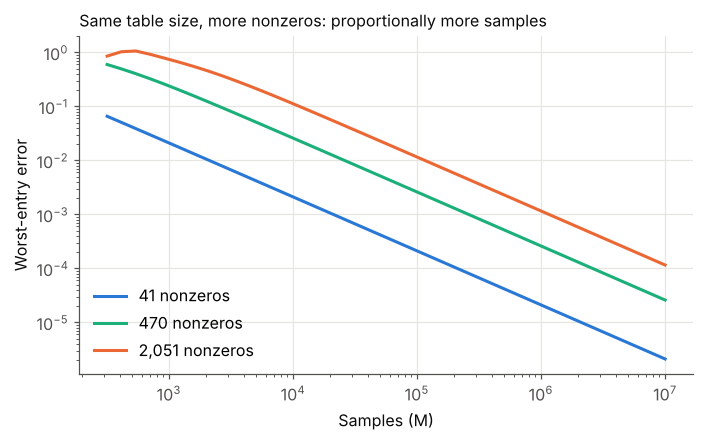

In [12]:
size = 64                                      # 64 x 64 table
fig, ax = plt.subplots(figsize=(7.2, 4))
for nnz_frac, col in [(1/64, BLUE), (1/8, AQUA), (1/2, ORANGE)]:
    t_rng = np.random.default_rng(9)
    mask = t_rng.random((size, size)) < nnz_frac
    T = np.where(mask, t_rng.uniform(-0.9, 0.9, (size, size)), 0.0)
    errs = []
    for Mt in M_grid:
        U = expected_table(T, Mt)
        errs.append(np.max(np.abs((U - U.conj()).imag / 2 - T)))
    ax.loglog(M_grid, errs, color=col, label=f"{np.count_nonzero(T):,} nonzeros")
ax.set_xlabel("Samples (M)"); ax.set_ylabel("Worst-entry error")
ax.set_title("Same table size, more nonzeros: proportionally more samples",
             loc="left", color=INK, fontsize=10.5)
ax.legend(loc="lower left"); plt.show()

### 3.4 A toy classifier on top

The real algorithm feeds the block encoding into a quantum linear solver (QSVT) to train a ridge classifier. Here we **emulate that solver classically** on the sketched table, to show how sketching error flows through to predictions.

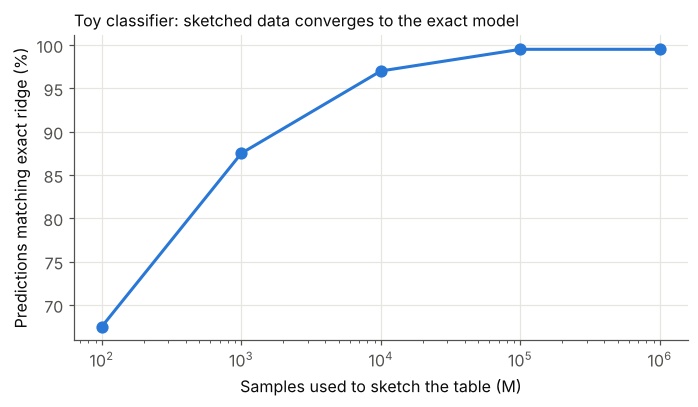

In [13]:
c_rng = np.random.default_rng(11)
X = np.where(c_rng.random((48, 16)) < 0.25, c_rng.uniform(-0.9, 0.9, (48, 16)), 0.0)
w_true = c_rng.normal(size=16)
y = np.sign(X @ w_true + 1e-9)
X_test = np.where(c_rng.random((200, 16)) < 0.25, c_rng.uniform(-0.9, 0.9, (200, 16)), 0.0)

def ridge(Xm, y, lam=0.1):
    return np.linalg.solve(Xm.T @ Xm + lam * np.eye(Xm.shape[1]), Xm.T @ y)

exact_pred = np.sign(X_test @ ridge(X, y))
agree = []
M_cls = [10**k for k in range(2, 7)]
for Mt in M_cls:
    U = sketch_table(X, Mt, np.random.default_rng(Mt))
    X_sk = ((U - U.conj()) / 2j).real           # what the block encoding exposes
    agree.append(np.mean(np.sign(X_test @ ridge(X_sk, y)) == exact_pred))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.semilogx(M_cls, np.array(agree) * 100, "o-", color=BLUE, ms=7)
ax.set_xlabel("Samples used to sketch the table (M)")
ax.set_ylabel("Predictions matching exact ridge (%)")
ax.set_title("Toy classifier: sketched data converges to the exact model",
             loc="left", color=INK, fontsize=10.5)
plt.show()

**Technical note: what the full algorithm adds.** A real QOS classifier also needs *index oracles* (which columns are nonzero in each row), an *amplification* step that rescales the block encoding from $A/s$ to $A/2$ (Theorem D.23), *QSVT* to invert $X^\top X+\lambda I$, and *readout* by measurement. Each multiplies the sample cost, and sparsity $s$ enters each time. In simulation the project measured, as a function of $s$:

| Building block | Proof exponent | Measured |
|---|---|---|
| Index oracle | $s^{3}$ | $s^{2.2}$ |
| Amplified block encoding | $s^{5}$ | $s^{3.1\text{–}3.3}$ |

Reference functions: `q_oracle_sketch_matrix_index`, `utils.block_encoding_from_sparse_oracles` and `qsvt.py` in the authors' repository; the project's faithful versions are in `experiments/qos_tightness/`.

### 3.5 Optional: check against the authors' reference implementation

If the reference repository and its dependencies (JAX, `pyqsp`) are available, e.g. in the project's `.venv-qos-ref` environment, this cell confirms our NumPy sketches match it exactly. Otherwise it explains how to run it.

In [14]:
import sys
from pathlib import Path

REF = Path("../reference/quantum-oracle-sketching")   # path inside qos-rbc-experiments
try:
    sys.path.insert(0, str(REF.resolve()))
    import jax, jax.numpy as jnp
    jax.config.update("jax_enable_x64", True)
    import qos
    ref_bool, _ = qos.q_oracle_sketch_boolean(jnp.array(f), 5_000)
    ref_elem, _ = qos.q_oracle_sketch_matrix_element(jnp.array(A), 20_000)
    U = expected_table(A, 20_000)
    print(f"Boolean oracle, ours vs reference: {np.max(np.abs(np.array(ref_bool) - expected_oracle(f, 5_000))):.1e}")
    print(f"Matrix oracle,  ours vs reference: {np.max(np.abs(np.array(ref_elem).reshape(A.shape) - (U - U.conj()) / 2j)):.1e}")
except Exception as err:
    print("Reference implementation not available here:", type(err).__name__, "-", err)
    print("Run this cell under .venv-qos-ref from the notebooks/ folder of qos-rbc-experiments.")

Reference implementation not available here: ModuleNotFoundError - No module named 'qos'
Run this cell under .venv-qos-ref from the notebooks/ folder of qos-rbc-experiments.


## Part 4. What happens at bank scale

**In plain English:** the toy examples work because the tables are small and sparse. Real bank data breaks both assumptions.

### 4.1 Real data isn't sparse in columns

The paper's guarantee needs every row **and every column** to have few nonzeros. In text, common words appear in most documents. Below: synthetic text with real-language word frequencies (10 commonest words removed, like stop-word removal). In the real CFPB complaints, the busiest word appeared in **58–71%** of complaints.

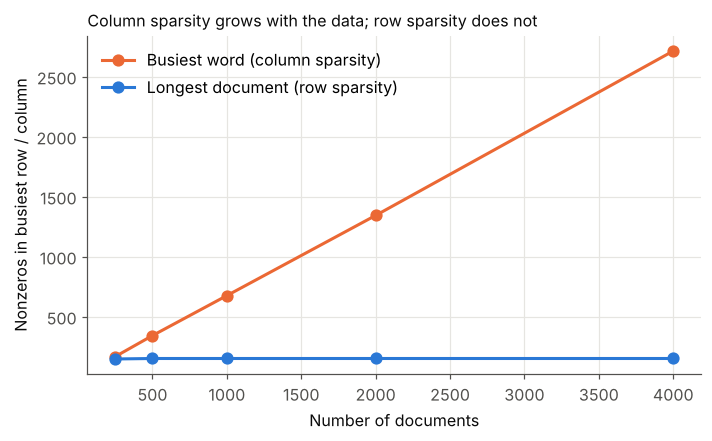

250: 67%, 500: 68%, 1000: 68%, 2000: 67%, 4000: 68% of documents contain the busiest word


In [15]:
V = 20_000
word_p = 1 / np.arange(1, V + 1)          # Zipf's law
word_p[:10] = 0                           # drop the 10 commonest words
word_p /= word_p.sum()

def make_corpus(n_docs, rng, class_p=None):
    docs, labels = [], []
    for _ in range(n_docs):
        y_ = rng.integers(0, 2)
        p = word_p if class_p is None else class_p[y_]
        words = rng.choice(V, size=rng.integers(40, 160), p=p)
        docs.append(" ".join(f"w{w}" for w in words)); labels.append(y_)
    return docs, np.array(labels)

sizes = [250, 500, 1_000, 2_000, 4_000]
corpus, _ = make_corpus(max(sizes), np.random.default_rng(11))
row_s, col_s = [], []
for n_docs in sizes:
    Xc = CountVectorizer(token_pattern=r"\S+").fit_transform(corpus[:n_docs])
    row_s.append(np.diff(Xc.indptr).max()); col_s.append(np.diff(Xc.tocsc().indptr).max())

fig, ax = plt.subplots(figsize=(7.2, 4))
ax.plot(sizes, col_s, "o-", color=ORANGE, ms=7, label="Busiest word (column sparsity)")
ax.plot(sizes, row_s, "o-", color=BLUE, ms=7, label="Longest document (row sparsity)")
ax.set_xlabel("Number of documents"); ax.set_ylabel("Nonzeros in busiest row / column")
ax.set_title("Column sparsity grows with the data; row sparsity does not",
             loc="left", color=INK, fontsize=10.5)
ax.legend(loc="upper left"); plt.show()
print(", ".join(f"{n_docs}: {c/n_docs:.0%}" for n_docs, c in zip(sizes, col_s)), "of documents contain the busiest word")

### 4.2 The bill for one query

The paper's sample cost grows like $s^{7}\kappa^{4}\gamma^{-4}$. Using the measured, gentler sparsity exponent from Part 3, the project estimated the samples needed for **one** block-encoding query. At a billion samples per second (from `results/FINAL_SUMMARY.md`; extrapolated, orders of magnitude only):

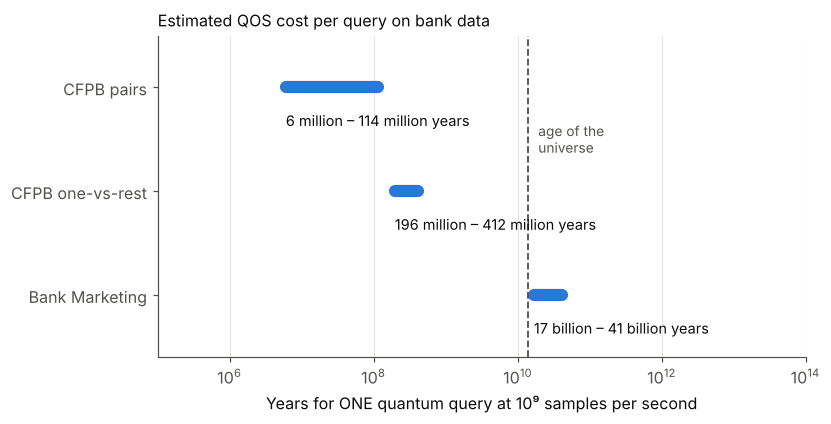

In [16]:
per_query = {                                   # samples per A/2 query, eps = 1e-2
    "CFPB pairs":       (1.9e23, 3.6e24),
    "CFPB one-vs-rest": (6.2e24, 1.3e25),
    "Bank Marketing":   (5.3e26, 1.3e27),
}
rate, year = 1e9, 3.156e7

def in_words(years):
    for scale, word in [(1e9, "billion"), (1e6, "million"), (1e3, "thousand")]:
        if years >= scale:
            return f"{years/scale:.0f} {word}"
    return f"{years:.0f}"

fig, ax = plt.subplots(figsize=(7.6, 3.8))
names = list(per_query)
for i, name in enumerate(names):
    lo, hi = (v / rate / year for v in per_query[name])
    ax.plot([lo, hi], [i, i], color=BLUE, lw=8, solid_capstyle="round")
    ax.text(lo, i + 0.32, f"{in_words(lo)} – {in_words(hi)} years", va="center", color=INK, fontsize=9.5)
ax.axvline(1.38e10, color=MUTED, lw=1.2, ls="--")
ax.text(1.38e10 * 1.4, 0.5, "age of the\nuniverse", color=MUTED, fontsize=9, va="center")
ax.set_xscale("log"); ax.set_xlim(1e5, 1e14)
ax.set_yticks(range(len(names)), names); ax.set_ylim(len(names) - 0.4, -0.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Years for ONE quantum query at 10⁹ samples per second")
ax.set_title("Estimated QOS cost per query on bank data", loc="left", color=INK, fontsize=10.5)
plt.show()

### 4.3 And classical needs only kilobytes

QOS's selling point is saving memory. A streaming classical learner with a fixed-size hashed weight table (single pass) needs very little. On real CFPB data the project measured **16–32 KiB** for 95% of full accuracy; the same effect on synthetic data:

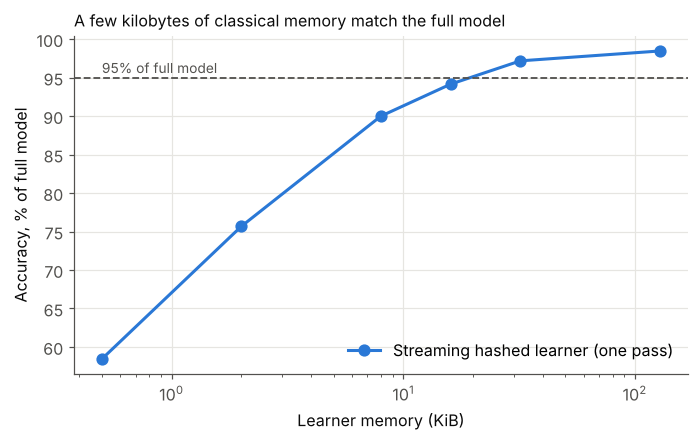

In [17]:
topic = {0: np.arange(150, 450), 1: np.arange(450, 750)}
class_p = {}
for y_, words in topic.items():
    p = word_p.copy(); p[words] *= 2.5; class_p[y_] = p / p.sum()
data_rng = np.random.default_rng(21)
train_docs, y_train = make_corpus(6_000, data_rng, class_p)
test_docs, y_test = make_corpus(2_000, data_rng, class_p)
tokens = lambda docs: [d.split() for d in docs]

vec = CountVectorizer(token_pattern=r"\S+", binary=True).fit(train_docs)
full_acc = LogisticRegression(max_iter=2000).fit(vec.transform(train_docs), y_train) \
                                            .score(vec.transform(test_docs), y_test)
budgets, accs = [64, 256, 1024, 2048, 4096, 16384], []
for k in budgets:
    hasher = FeatureHasher(n_features=k, input_type="string", alternate_sign=True)
    clf = SGDClassifier(loss="log_loss", alpha=1e-4, random_state=42)
    for i in range(0, len(train_docs), 500):
        clf.partial_fit(hasher.transform(tokens(train_docs[i:i+500])), y_train[i:i+500], classes=[0, 1])
    accs.append(clf.score(hasher.transform(tokens(test_docs)), y_test))

kib = [k * 8 / 1024 for k in budgets]
fig, ax = plt.subplots(figsize=(7.2, 4))
ax.semilogx(kib, np.array(accs) / full_acc * 100, "o-", color=BLUE, ms=7, label="Streaming hashed learner (one pass)")
ax.axhline(95, color=MUTED, lw=1.2, ls="--"); ax.text(kib[0], 95.6, "95% of full model", color=MUTED, fontsize=9)
ax.set_xlabel("Learner memory (KiB)"); ax.set_ylabel("Accuracy, % of full model")
ax.set_title("A few kilobytes of classical memory match the full model", loc="left", color=INK, fontsize=10.5)
ax.legend(loc="lower right"); plt.show()

## Takeaways

| | |
|---|---|
| **The mechanism works** | One sample = one small gate; the gates add up to an oracle without storing data (Parts 1, 3). |
| **Every use costs samples** | Each oracle use needs a fresh batch, and readout needs many repetitions (Part 2). |
| **Cost grows with sparsity** | Denser tables need more samples, and real data is dense in columns (Parts 3–4). |
| **At bank scale the bill is astronomical** | Millions of years per query on CFPB, even with the measured, gentler scaling (Part 4). |
| **Not a disproof** | The theorem is a correct worst-case guarantee; untested on bank data with bounded row *and* column sparsity. See the report's *Candidate Bank Data* and *Next Steps*. |

**Where to go next in code:** the authors' `qos.py` (all oracle sketches), `qsvt.py` (polynomials and angles), and this project's `experiments/qos_tightness/` (verified sign polynomials, amplification, scaling sweeps).